In [3]:
import pandas as pd
import random

# statsmodels의 fomula api import
import statsmodels.formula.api as smf

# 난수 시드 설정
random.seed(1)

# 데이터 생성
x = list(range(1, 11))
y = [2 * i + 1 + random.gauss(0, 1) for i in x] # 2 * x + 1에 근사하도록

# DataFrame 생성
data = pd.DataFrame({ 'x': x, 'y': y })

# OLS (최소 제곱법) 회귀 모델 생성 및 학습
# 'y'를 종속 변수로 하고 다른 특성 (x)을 독립 변수
model = smf.ols(formula='y ~ x', data=data).fit() # x의 값을 가지고 y를 모델링하는 선형회귀 모델을 OLS로 만듦

# 모델 요약 결과 출력
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.977
Model:                            OLS   Adj. R-squared:                  0.975
Method:                 Least Squares   F-statistic:                     345.0
Date:                Sat, 10 Oct 2026   Prob (F-statistic):           7.28e-08
Time:                        15:52:25   Log-Likelihood:                -12.020
No. Observations:                  10   AIC:                             28.04
Df Residuals:                       8   BIC:                             28.65
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.7622      0.615      2.866      0.0

In [ ]:
# scikit-learn의 ensemble 알고리즘 중 RandomForestClassifier import
# statsmodels는 통계학이라는 수학적 이론에 기반해서 작성이 된다. 통계학을 벗어나는 건 statsmodels에서는 적합하지 않음
# 반면에 scikit-learn은 기계학습과 관련된 알고리즘, 도구를 사용할 수 있다.
from sklearn.ensemble import RandomForestClassifier

# 모델 평가를 위한 데이터 분할 (split) 함수 import
from sklearn.model_selection import train_test_split

# 모델의 정확도 (accuracy)를 측정하는 함수 import
from sklearn.metrics import accuracy_score

# 예제 데이터셋 (유방암 데이터) 로드 함수 import
# OpenSource 모듈에도 이런 데이터셋이 있다.
from sklearn.datasets import load_breast_cancer

# 데이터 로드 및 분할
cancer = load_breast_cancer()
x, y = cancer.data, cancer.target

# 학습/테스트 데이터셋 분할
# 학습할 때 사용될 데이터와 학습이 끝난 후 모델을 검증할 때 쓰는 데이터를 분리하는 것이 중요하다
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=42)

# Random Forest model 생성 및 학습
# RandomForest는 Classifier가 여러 개 모여 있는 것
# 예측할 때 복수의 사람에게 질의해서 종합적인 결과를 예측한다
# RandomForest, 혹은 ensemble 모형에서 중요한 것은 몇 개의 모델을 만들어서 답을 종합할 것인가
model = RandomForestClassifier(n_estimators=100) # n_estimators: 대상들의 개수
model.fit(x_train, y_train)

# 예측 및 정확도 평가
y_pred = model.predict(x_test)
accuracy = accuracy_score(y_test, y_pred)
print(accuracy) # 몇 퍼센트를 정확히 예측했는가

0.9707602339181286


In [8]:
from sklearn.metrics import classification_report
# 딥러닝 분석을 위한 tensorflow 임포트

## CIFAR-10 데이터셋 로드 및 전처리
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()
x_train, x_test = x_train/255.0, x_test/255.0

## MobileNetV2 기반 모델 구축
# 학습이 되어 있는 모델을 이용해서 fine-tuning
# MobileNetV2 모델을 이용해서 그 위에 모델을 구축
base_model = tf.keras.applications.MobileNetV2(weights='imagenet', include_top=False, input_shape=(160, 160, 3))
base_model.trainable = False
model = tf.keras.Sequential([
    tf.keras.layers.Resizing(160, 160),
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(10)
])

## 모델 컴파일
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

## 모델 학습
model.fit(x_train, y_train, epochs=3, validation_split=0.2)

## 예측 및 성능 평가
y_pred = tf.argmax(model.predict(x_test), axis=1)
print("\nTest Accuracy:", model.evaluate(x_test, y_test, verbose=0)[1])
print("\nClassification Report:\n", classification_report(y_test, y_pred))

 18882560/170498071 ━━━━━━━━━━━━━━━━━━━━ 27:01 11us/step

KeyboardInterrupt: 

                age           sex           bmi            bp            s1  \
count  4.420000e+02  4.420000e+02  4.420000e+02  4.420000e+02  4.420000e+02   
mean  -2.511817e-19  1.230790e-17 -2.245564e-16 -4.797570e-17 -1.381499e-17   
std    4.761905e-02  4.761905e-02  4.761905e-02  4.761905e-02  4.761905e-02   
min   -1.072256e-01 -4.464164e-02 -9.027530e-02 -1.123988e-01 -1.267807e-01   
25%   -3.729927e-02 -4.464164e-02 -3.422907e-02 -3.665608e-02 -3.424784e-02   
50%    5.383060e-03 -4.464164e-02 -7.283766e-03 -5.670422e-03 -4.320866e-03   
75%    3.807591e-02  5.068012e-02  3.124802e-02  3.564379e-02  2.835801e-02   
max    1.107267e-01  5.068012e-02  1.705552e-01  1.320436e-01  1.539137e-01   

                 s2            s3            s4            s5            s6  \
count  4.420000e+02  4.420000e+02  4.420000e+02  4.420000e+02  4.420000e+02   
mean   3.918434e-17 -5.777179e-18 -9.042540e-18  9.268604e-17  1.130318e-17   
std    4.761905e-02  4.761905e-02  4.761905e-02  4.

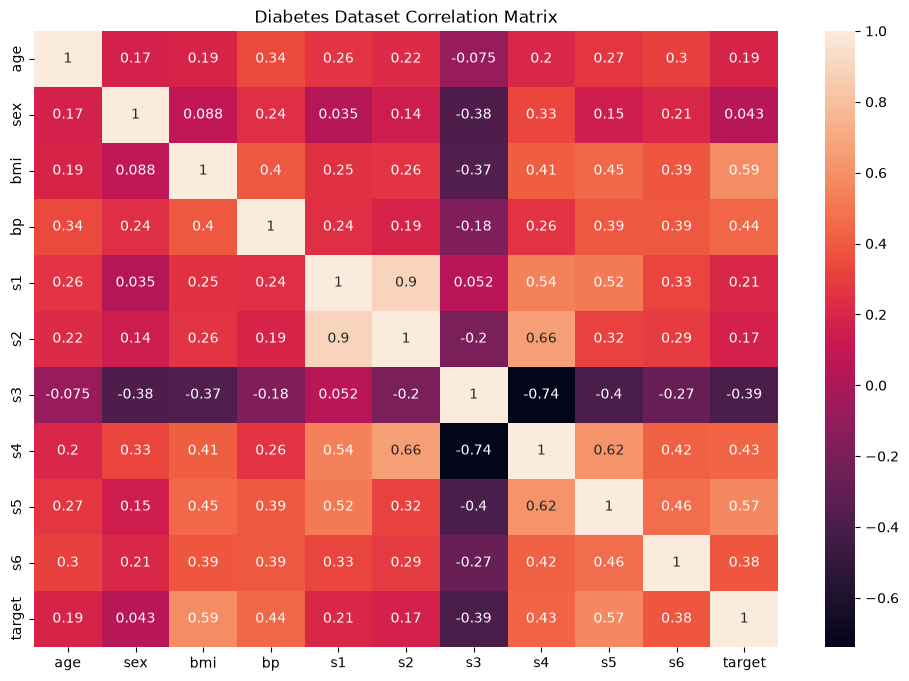

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_diabetes

# EDA: 데이터를 탐색하는 과정 - 데이터 분석을 할 때 어떤 모델을 세워야 할까 생각을 할 때 데이터를 전체적인 관점에서 크게 보는 과정
# 다 찔러보는 것
diabetes = load_diabetes()
df = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
df['target'] = diabetes.target

# DataFrame의 describe를 이용하여 기본 통계량 출력
print(df.describe())

# 상관 행렬 시각화
# 상관분석: column들 간의 유사도를 2차원으로 시각화
plt.figure(figsize=(12, 8))

# DataFrame의 각 column (변수)들 간의 상관 계수 (correleation coefficient)를 계산하고 corr_matrix로 저장
corr_matrix = df.corr()

# seaborn으로 corr_matrix를 heatmap으로 시각화
# 색이 하얄수록 관계성이 높은 변수
# -1 ~ 1 사이의 값
# 0이면 상관이 없음
# -1이면 완전히 반대됨
# 1이면 완전히 일치
sns.heatmap(corr_matrix, annot=True)
plt.title('Diabetes Dataset Correlation Matrix')
plt.show()

In [ ]:
import pandas as pd
import seaborn as sns

# 아이리스 데이터셋 로드 (붓꽃)
df = sns.load_dataset('iris')

# 기술 통계량
print('=== 기본 통계량 ===')
print(df.describe())

# 데이터 미리보기
print('\n=== 데이터 미리보기 ===')
print(df.head())

# 그룹별 통계정보
print('\n=== 품종별 평균값 ===')
print(df.groupby('species').mean())

=== 기본 통계량 ===
       sepal_length  sepal_width  petal_length  petal_width
count    150.000000   150.000000    150.000000   150.000000
mean       5.843333     3.057333      3.758000     1.199333
std        0.828066     0.435866      1.765298     0.762238
min        4.300000     2.000000      1.000000     0.100000
25%        5.100000     2.800000      1.600000     0.300000
50%        5.800000     3.000000      4.350000     1.300000
75%        6.400000     3.300000      5.100000     1.800000
max        7.900000     4.400000      6.900000     2.500000

=== 데이터 미리보기 ===
   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa

=== 품종별 평균값 ===
            sepal_length  

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 아이리스 데이터셋 로드
df = sns.load_dataset('iris')

# 서브플롯 설정
plt.figure(figsize=(9, 12))
plt.suptitle('iris dataset visualization', y=1.02, fontsize=14)

# 첫 번째 서브플롯: 꽃잎 길이 분포 (히스토그램)
sns.histplot(df['petal_length'], bins=10)
plt.title('petal length distribution')
plt.xlabel('petal length (cm)')

# 두 번째 서브플롯: 꽃잎 길치 vs. 너비 (산점도)
plt.subplot(4, 1, 2)
specieis_list = df['species'].unique()
colors = {'setosa': 'red', 'versicolor': 'green', 'virginica': 'blue'}

for species in species_list:
    species_data = df[df['species'] == species]
    # matplotlib를 이용하여 길이, 넓이를 산점도로 표시
    plt.scatter(
        species_data['petal_legnth'], species_data['petal_width'],
        c=colors[species], label=species
    )

plt.title('petal')

Text(0.5, 1.02, 'iris dataset visualization')

<Figure size 900x1200 with 0 Axes>